In [3]:
# IMPORTS

# pip install scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn import metrics


In [4]:
df = pd.read_csv("../dataset/cleaned/Sinetänsalmentie3.csv")
df.head(10)

,Timer(ms),Loc(m),CElev(m),Roll(deg),Pitch(deg),Yaw(deg),AccX,AccY,AccZ,GyrX,GyrY,GyrZ,Speed_kmh,Frostbumps
0,41518221.1,5004.281,10.387099,-0.4559,-15.5989,-0.3722,2.84113,-0.08279,10.00145,0.00626,0.00012,-0.01994,36.09,0
1,41518223.6,5004.306,9.957436,-0.4534,-15.5984,-0.3753,2.73611,0.04904,10.08783,0.01199,0.00362,-0.02091,36.09,0
2,41518226.1,5004.331,10.055480,-0.4510,-15.5976,-0.3791,2.72616,-0.06434,10.15394,0.00938,0.00628,-0.02554,36.09,0
3,41518228.6,5004.356,9.814133,0.0187,-15.4860,-0.5073,2.86240,-0.03215,9.99081,0.00756,-0.01024,-0.01908,36.09,0
4,41518231.1,5004.381,9.692896,0.0202,-15.4859,-0.5105,3.02184,-0.09944,9.90836,0.00467,0.00091,-0.02129,36.09,0
5,41518233.6,5004.406,9.700895,0.0219,-15.4851,-0.5138,2.97610,-0.07237,9.91381,0.00561,0.00500,-0.02210,36.09,0
6,41518236.1,5004.431,9.744065,0.0246,-15.4849,-0.5171,2.86745,-0.02517,9.94320,0.01283,0.00142,-0.02218,36.09,0
7,41518238.6,5004.456,9.681981,0.0270,-15.4848,-0.5202,2.81419,-0.10197,9.90092,0.01078,0.00115,-0.02130,36.09,0
8,41518241.1,5004.481,9.584630,0.0296,-15.4849,-0.5234,2.93214,-0.14487,9.83444,0.01194,-0.00060,-0.02161,36.09,0
9,41518243.6,5004.507,9.374599,0.0319,-15.4847,-0.5269,2.91693,-0.11759,9.69024,0.00963,0.00106,-0.02315,36.09,0


## Correlations

<Axes: >

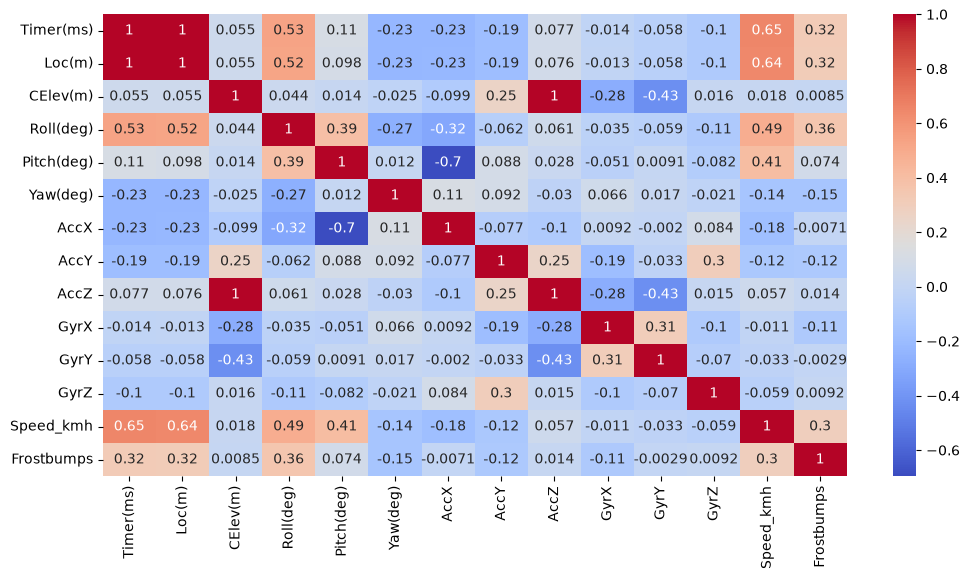

In [6]:
correlatinos = df.corr(numeric_only=True)
plt.figure(figsize=(12,6))
sns.heatmap(correlatinos, annot=True, cmap='coolwarm')

interval columns not set, guessing: ['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)', 'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Speed_kmh', 'Frostbumps']


<Axes: >

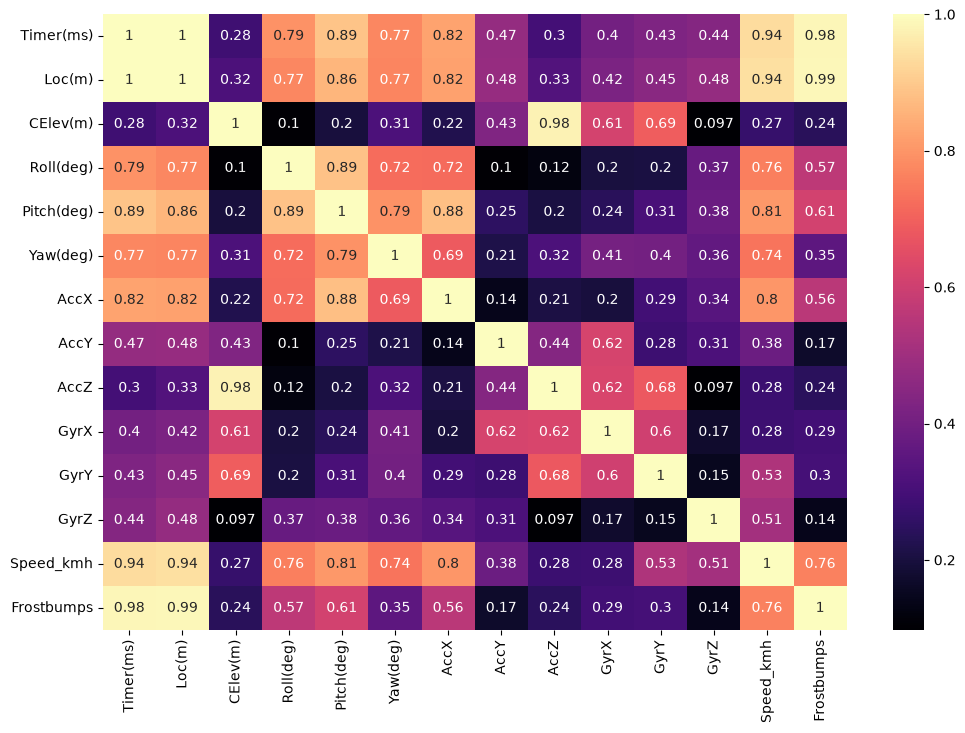

In [9]:
import phik

phik_matrix = df.phik_matrix()

plt.figure(figsize=(12,8))

sns.heatmap(phik_matrix, annot=True, cmap='magma')

## VIF-data

In [11]:

pd.set_option('display.float_format', '{:.2f}'.format)

from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select numerical features (exclude target)
X = df.select_dtypes(include='number').drop(columns=['Frostbumps'])

# Calculate VIF
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [
    variance_inflation_factor(X.values, i)
    for i in range(X.shape[1])
]

print(vif_data.sort_values(by='VIF', ascending=False))

       Feature      VIF
0    Timer(ms) 10175.71
1       Loc(m) 10067.92
8         AccZ   970.94
2     CElev(m)   967.96
12   Speed_kmh     5.06
4   Pitch(deg)     3.87
6         AccX     2.61
3    Roll(deg)     1.86
10        GyrY     1.32
7         AccY     1.31
9         GyrX     1.19
11        GyrZ     1.17
5     Yaw(deg)     1.17


In [30]:
# 1. Separate features and target
X = df.drop(columns=['Frostbumps'])
y = df['Frostbumps']

# 2. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


## Fisher score

In [32]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

def fisher_score(X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y)
    overall_mean = X.mean(axis=0)

    numerator = np.zeros(X.shape[1])
    denominator = np.zeros(X.shape[1])

    for c in np.unique(y):
        Xc = X[y == c]
        n_c = Xc.shape[0]
        numerator += n_c * (Xc.mean(axis=0) - overall_mean) ** 2
        denominator += n_c * Xc.var(axis=0)

    return numerator / (denominator + 1e-12)

In [39]:
X = df.drop(columns=["Frostbumps"])   # replace "target" with your label column
y = df["Frostbumps"]

scores = fisher_score(X, y)
result = pd.DataFrame({"feature": X.columns, "fisher_score": scores}).sort_values("fisher_score", ascending=False)
result.sort_values(by="fisher_score", ascending=False, inplace=True)
result

C:\Users\Niko Vuokila\AppData\Local\Temp\ipykernel_23392\549437347.py:6: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  result.sort_values(by="fisher_score", ascending=False, inplace=True)


,feature,fisher_score
3,Roll(deg),0.14
0,Timer(ms),0.12
1,Loc(m),0.11
12,Speed_kmh,0.10
5,Yaw(deg),0.02
7,AccY,0.01
9,GyrX,0.01
4,Pitch(deg),0.01
8,AccZ,0.00
11,GyrZ,0.00


In [41]:
df.columns

Index(['Timer(ms)', 'Loc(m)', 'CElev(m)', 'Roll(deg)', 'Pitch(deg)',
       'Yaw(deg)', 'AccX', 'AccY', 'AccZ', 'GyrX', 'GyrY', 'GyrZ', 'Speed_kmh',
       'Frostbumps'],
      dtype='str')

In [42]:
df['Frostbumps'].value_counts()

Frostbumps
0    11989
1     6139
Name: count, dtype: int64

In [48]:
summary = df.groupby("run_id").agg(
    n=("Timer(ms)", "size"),
    dt_ms=("Timer(ms)", lambda s: s.diff().median()),
    speed_mean=("Speed_kmh", "mean"),
    speed_max=("Speed_kmh", "max"),
    accz_std=("AccZ", "std"),
    gyry_std=("GyrY", "std"),
    bump_rows=("Frostbumps", "sum"),
    bump_frac=("Frostbumps", "mean"),
)
print(summary)

KeyError: 'run_id'

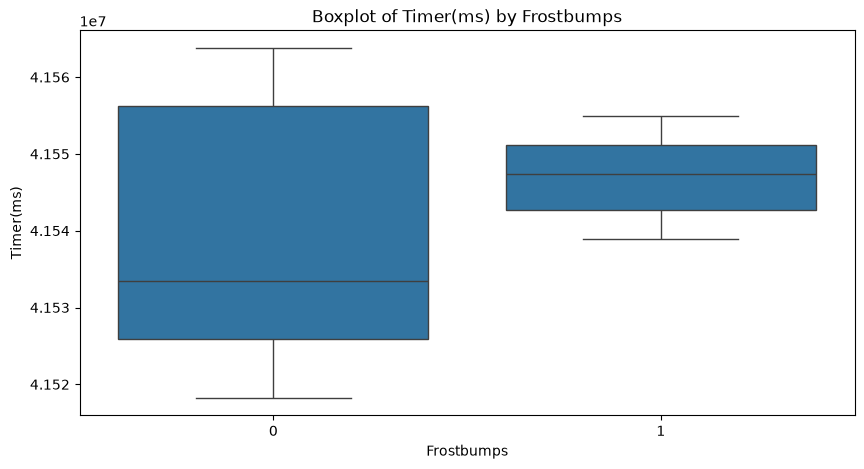

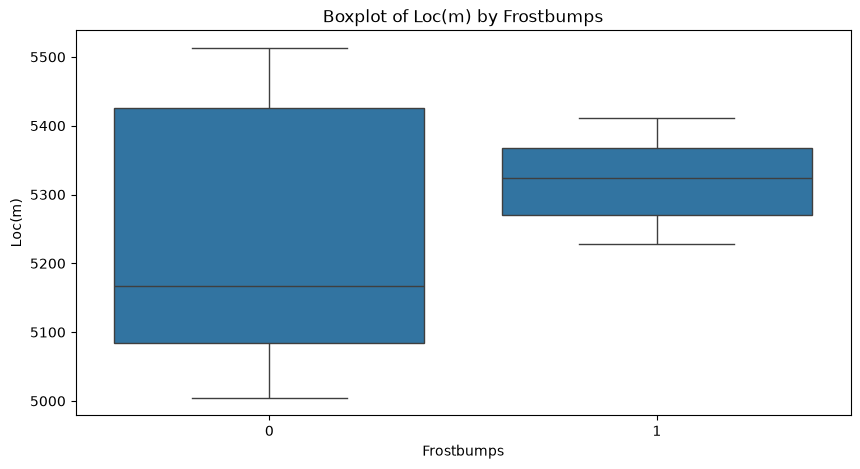

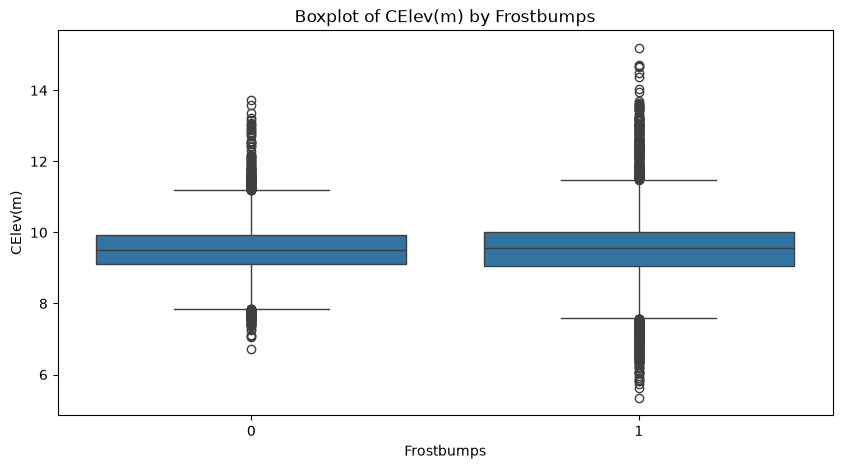

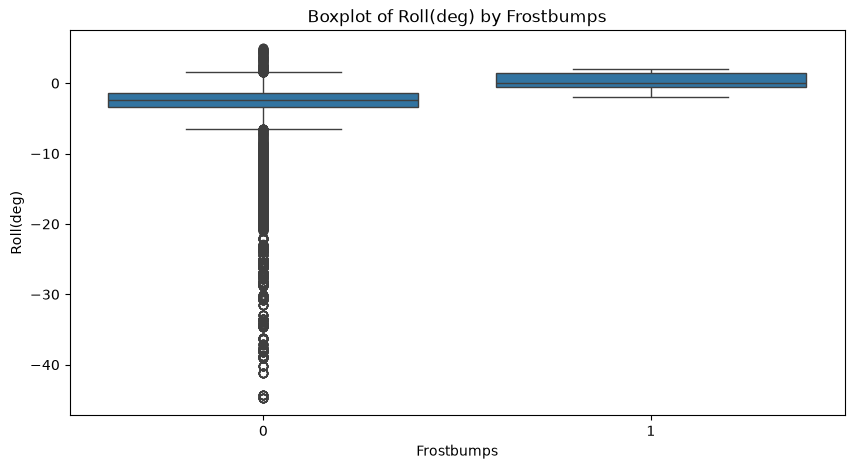

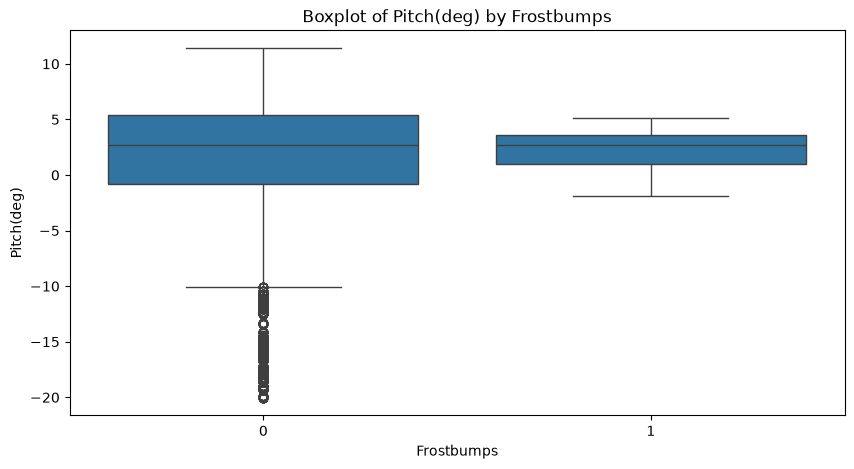

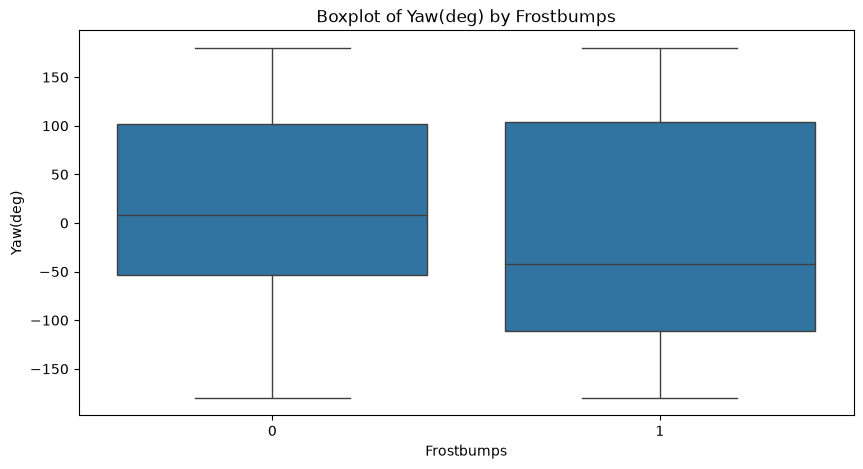

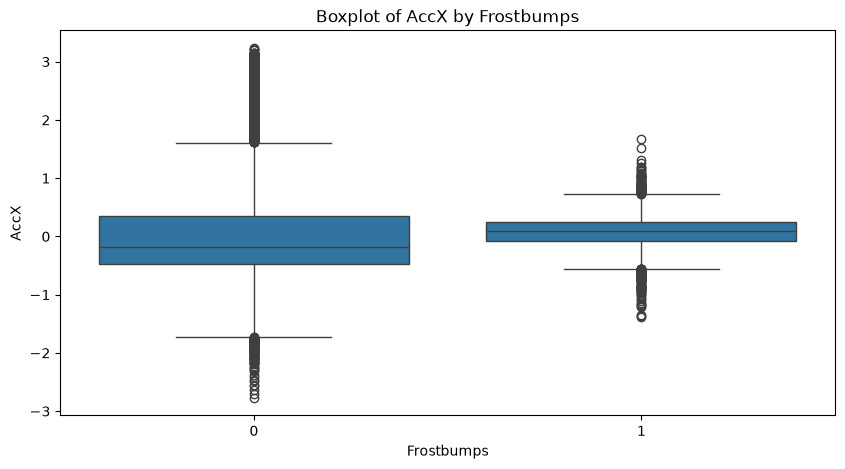

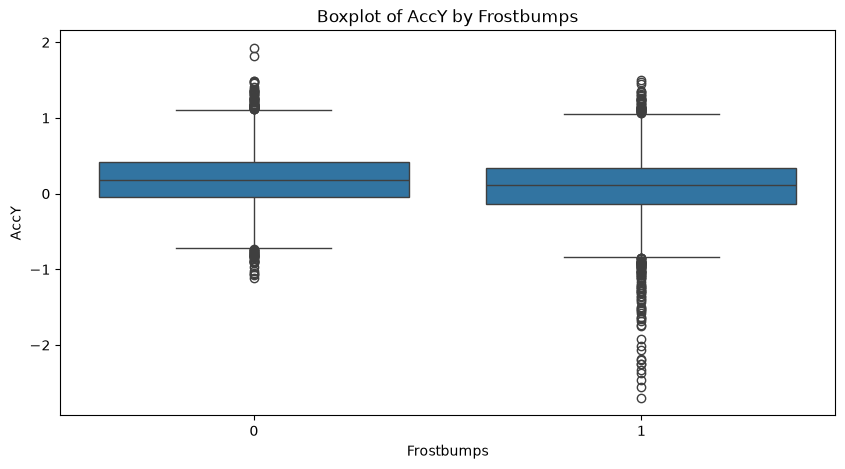

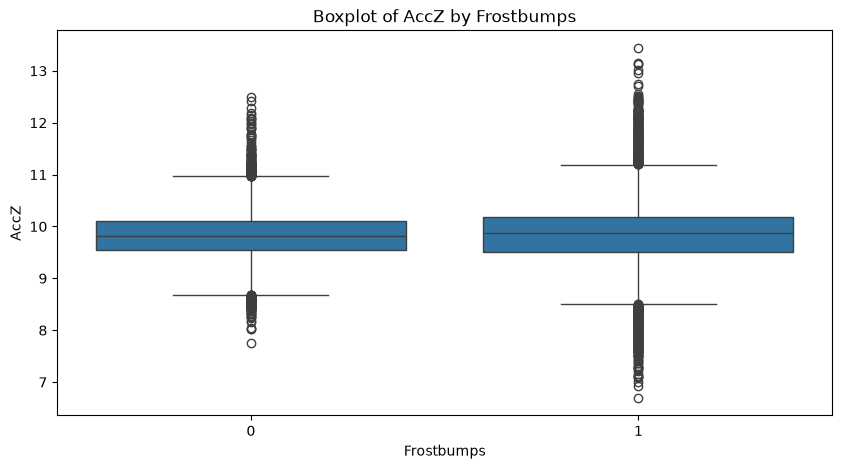

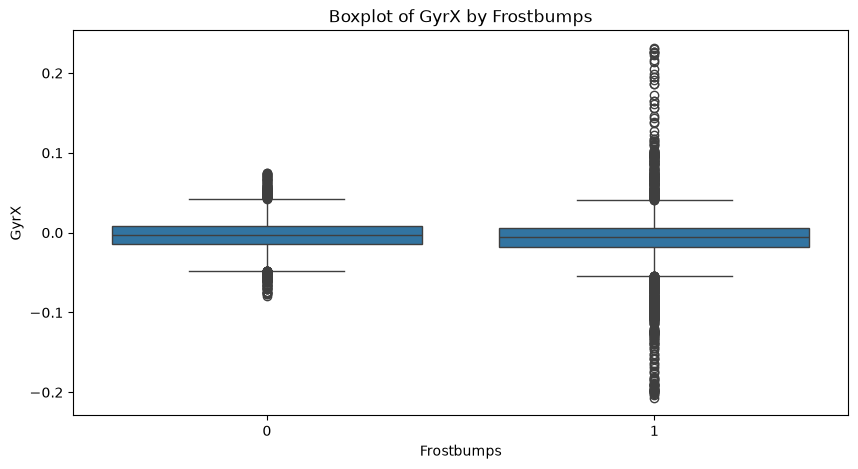

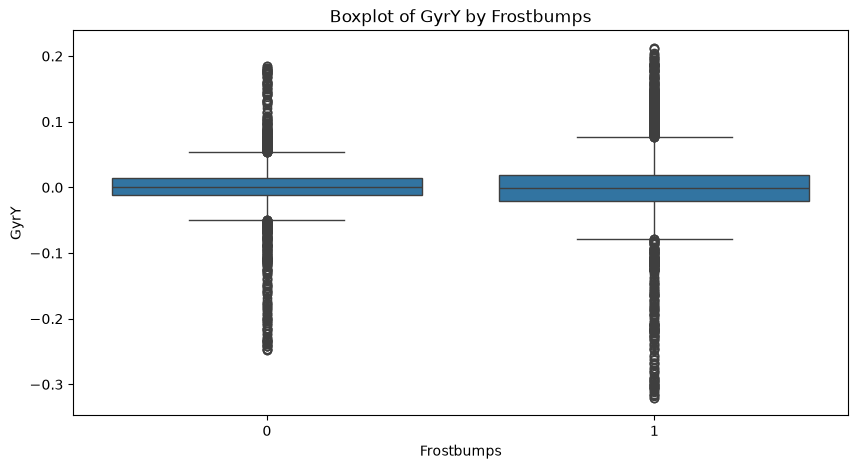

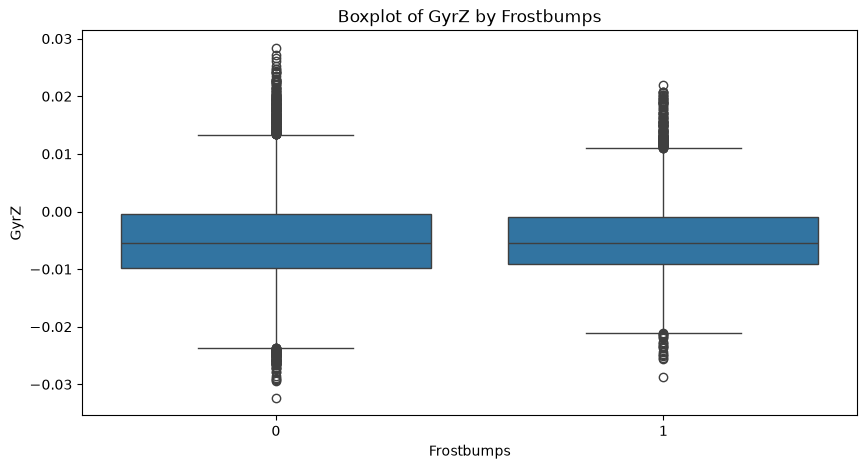

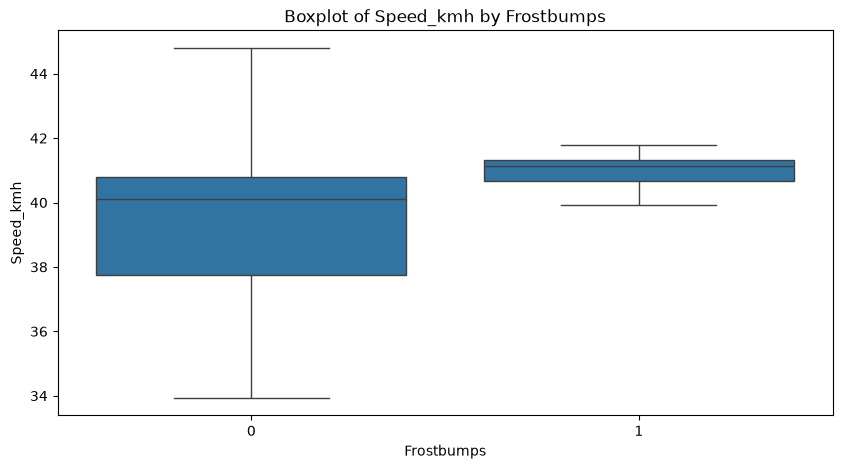

In [ ]:
for x in df.columns:
    if x != 'Frostbumps':
        plt.figure(figsize=(10, 5))
        sns.boxplot(x='Frostbumps', y=x, data=df)
        plt.title(f'Boxplot of {x} by Frostbumps')
        plt.show()

In [44]:
df['Frostbumps'].value_counts()

Frostbumps
0    11989
1     6139
Name: count, dtype: int64